# Customer Sentiment & Text Analytics of Indian Banking and Fintech Mobile Applications

### A Text Mining and Sentiment Analysis Project

---

## Executive Summary

Mobile banking and fintech applications have become the primary channel through which Indian
consumers interact with their financial service providers. User reviews left on app stores are a
rich, unstructured source of customer feedback that, when properly mined, can reveal specific
operational pain points, competitive positioning, and priorities for product investment.

This project analyzes **12,000 user reviews** collected across six leading applications —
**HDFC Bank, ICICI iMobile and YONO SBI** (traditional banks) and **Paytm, PhonePe and Groww**
(fintech platforms) — using a complete text-analytics pipeline: text cleaning and normalization,
linguistic feature extraction, lexicon-based and lexical-resource-based sentiment scoring,
emotion profiling, aspect-level sentiment mining, and comparative benchmarking across
applications.

The objective is to answer three business questions:

1. **How satisfied are users of each application**, and how does sentiment compare with the
   star ratings they already leave?
2. **What specific themes** (login, payments, customer support, performance, UI/UX) are driving
   positive vs. negative experiences?
3. **Which app(s) require the most urgent product/operations attention**, and what should be
   prioritized?

---


## 1. Environment Setup

The libraries below cover text preprocessing, lexicon-based sentiment scoring, emotion lexicons,
and standard data-visualization tooling.


In [4]:
# One-time installs
!pip -q install nltk textblob wordcloud pyspellchecker lemmagen3 scikit-learn seaborn afinn nrclex --upgrade


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.0/625.0 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 101.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.4/319.4 kB 16.5 MB/s eta 0:00:00


In [5]:
import pandas as pd
import numpy as np
import re, string, time
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')
nltk.download('sentiwordnet')
nltk.download('averaged_perceptron_tagger_eng')

from nltk.tokenize import word_tokenize, wordpunct_tokenize
from nltk.corpus import stopwords, sentiwordnet as swn
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk import pos_tag


from textblob import TextBlob
from wordcloud import WordCloud
from spellchecker import SpellChecker
from afinn import Afinn
from nrclex import NRCLex

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer

pd.set_option('display.max_colwidth', 120)
sns.set_style('whitegrid')
print("Environment ready.")


Environment ready.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package sentiwordnet to /root/nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-t

## 2. Dataset Overview & Exploratory Data Analysis

**Data dictionary:** each record is one app-store review with fields for the reviewing app, its
segment (Bank / Fintech), the 1–5 star rating given by the user, the free-text review, thumbs-up
count, date, app version, and whether the company replied.


In [6]:
import os
candidates = ['banking_app_reviews.csv', '/content/banking_app_reviews.csv']
file_path = next((p for p in candidates if os.path.exists(p)), None)
if file_path is None:
    from google.colab import files
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]

df = pd.read_csv(file_path)
print("Shape:", df.shape)
df.head(3)


Saving banking_app_reviews.csv to banking_app_reviews (1).csv
Shape: (12000, 10)


,row_no,review_id,app,group,rating,review,thumbs_up,date,app_version,company_replied
0,1,0bc6ffcc-0a7f-48d3-b018-db822a1271ed,HDFC Bank,Bank,2,I am unable to register on the HDFC Bank app despite having a strong and stable internet connection. The app repeate...,0,2026-08-09,11.3.3,Yes
1,2,70f582e6-b28e-4594-bec8-12003b160b85,HDFC Bank,Bank,1,What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is...,0,2026-07-22,11.3.3,Yes
2,3,554e7d45-657e-4b4c-bc2a-09843632a793,HDFC Bank,Bank,1,"App Reflects the Bank's Current State The app is unusable. It won't let me sign in and keeps showing, ""You seem to b...",0,2026-07-16,11.3.3,Yes


In [7]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   row_no           12000 non-null  int64 
 1   review_id        12000 non-null  object
 2   app              12000 non-null  object
 3   group            12000 non-null  object
 4   rating           12000 non-null  int64 
 5   review           12000 non-null  object
 6   thumbs_up        12000 non-null  int64 
 7   date             12000 non-null  object
 8   app_version      11492 non-null  object
 9   company_replied  12000 non-null  object
dtypes: int64(3), object(7)
memory usage: 937.6+ KB

Missing values per column:
 row_no               0
review_id            0
app                  0
group                0
rating               0
review               0
thumbs_up            0
date                 0
app_version        508
company_replied      0
dtype: int64


In [8]:
print("Reviews per app:\n", df['app'].value_counts())
print("\nSegment split (Bank vs Fintech):\n", df['group'].value_counts())
print("\nStar-rating distribution:\n", df['rating'].value_counts().sort_index())


Reviews per app:
 app
HDFC Bank        2000
ICICI iMobile    2000
YONO SBI         2000
Groww            2000
Paytm            2000
PhonePe          2000
Name: count, dtype: int64

Segment split (Bank vs Fintech):
 group
Bank       6000
Fintech    6000
Name: count, dtype: int64

Star-rating distribution:
 rating
1    7108
2     977
3     837
4     805
5    2273
Name: count, dtype: int64


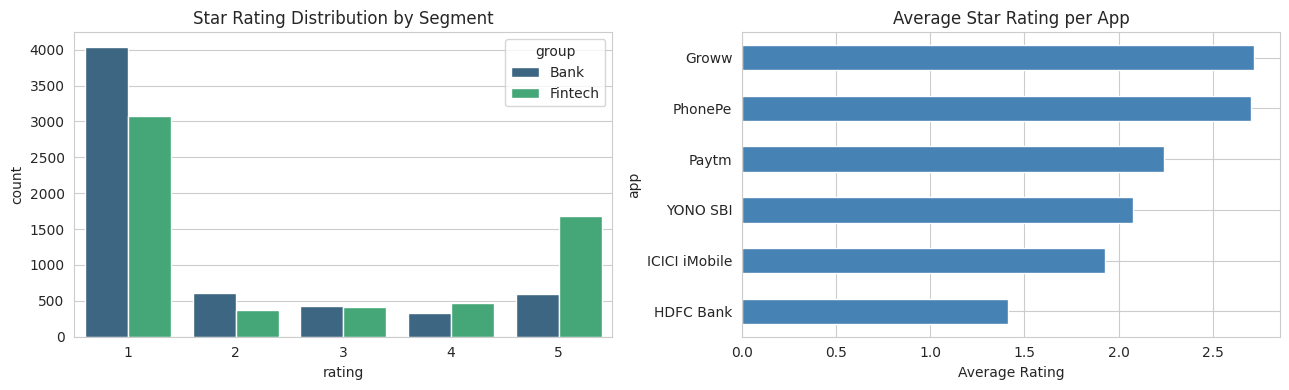

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='rating', hue='group', ax=ax[0], palette='viridis')
ax[0].set_title('Star Rating Distribution by Segment')
df.groupby('app')['rating'].mean().sort_values().plot(kind='barh', ax=ax[1], color='steelblue')
ax[1].set_title('Average Star Rating per App')
ax[1].set_xlabel('Average Rating')
plt.tight_layout()
plt.show()


**Finding:** the dataset contains **12,000 reviews with no missing text**, evenly split
across the six apps (2,000 each) and evenly across the Bank/Fintech segments (6,000 each). Ratings
are strongly bimodal — **7,108 reviews are 1-star** and **2,273 are 5-star** — which is typical of
app-store feedback, where users are most likely to write a review when they are either very
frustrated or very satisfied. **HDFC Bank (1.41★) and ICICI iMobile (1.93★)** are the lowest-rated
apps in the sample, while **Groww (2.72★) and PhonePe (2.70★)** are the highest-rated — an early
signal that fintech platforms in this sample outperform traditional bank apps on customer
satisfaction, which will be tested further using independent sentiment analysis.


## 3. Text Preprocessing Methodology

Raw review text is noisy: inconsistent casing, punctuation, elongated characters
("soooo slow"), typos, and filler words. A consistent preprocessing pipeline is required before
any quantitative modelling. Four steps are applied, each benchmarked below before being adopted
into the final pipeline.

### 3.1 Tokenization

Several tokenization strategies were compared on the same sample review to select the one best
suited to noisy, punctuation-heavy user reviews.


In [10]:
sample_review = df['review'].iloc[1]
print("SAMPLE REVIEW:\n", sample_review)


SAMPLE REVIEW:
 What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is just throwing random error saying checkin% customer credentials and validation. No way I can change it, i even visited my nearest branch but of no use


In [11]:
print("Standard tokenizer:\n", word_tokenize(sample_review), "\n")
print("Punctuation-splitting tokenizer:\n", wordpunct_tokenize(sample_review), "\n")

treebank_wt = nltk.TreebankWordTokenizer()
print("Treebank-convention tokenizer:\n", treebank_wt.tokenize(sample_review), "\n")

regex_wt = nltk.RegexpTokenizer(pattern=r'\w+', gaps=False)
print("Alphanumeric-only tokenizer:\n", regex_wt.tokenize(sample_review))


Standard tokenizer:
 ['What', 'a', 'pathetic', 'app', 'for', 'bank', 'which', 'is', 'leading', 'the', 'charts', '.', 'i', 'am', 'not', 'able', 'to', 'log', 'into', 'my', 'account', 'for', 'a', 'week', 'now', '.', 'It', 'is', 'just', 'throwing', 'random', 'error', 'saying', 'checkin', '%', 'customer', 'credentials', 'and', 'validation', '.', 'No', 'way', 'I', 'can', 'change', 'it', ',', 'i', 'even', 'visited', 'my', 'nearest', 'branch', 'but', 'of', 'no', 'use'] 

Punctuation-splitting tokenizer:
 ['What', 'a', 'pathetic', 'app', 'for', 'bank', 'which', 'is', 'leading', 'the', 'charts', '.', 'i', 'am', 'not', 'able', 'to', 'log', 'into', 'my', 'account', 'for', 'a', 'week', 'now', '.', 'It', 'is', 'just', 'throwing', 'random', 'error', 'saying', 'checkin', '%', 'customer', 'credentials', 'and', 'validation', '.', 'No', 'way', 'I', 'can', 'change', 'it', ',', 'i', 'even', 'visited', 'my', 'nearest', 'branch', 'but', 'of', 'no', 'use'] 

Treebank-convention tokenizer:
 ['What', 'a', 'path

**Decision:** the general-purpose tokenizer and the punctuation-splitting tokenizer behave
almost identically on this corpus, while the alphanumeric-only tokenizer is the strictest,
dropping every punctuation mark and keeping only clean word tokens. Since the downstream goal is
a clean vocabulary for frequency and vector-space analysis (not punctuation-level analysis), an
**alphanumeric-token approach is adopted for the cleaning pipeline** below.

### 3.2 Cleaning, Stemming & Lemmatization

Text is lower-cased, elongated characters are collapsed, and punctuation/digits are stripped.
Words are then reduced to a common root using three different stemming algorithms and two
lemmatization approaches, compared side by side to justify the final choice.


In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'(.)\1\1+', r'\1', text)                       # helllooo -> hello
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)
df[['review', 'clean_review']].head(3)


,review,clean_review
0,I am unable to register on the HDFC Bank app despite having a strong and stable internet connection. The app repeate...,i am unable to register on the hdfc bank app despite having a strong and stable internet connection the app repeated...
1,What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is...,what a pathetic app for bank which is leading the charts i am not able to log into my account for a week now it is j...
2,"App Reflects the Bank's Current State The app is unusable. It won't let me sign in and keeps showing, ""You seem to b...",app reflects the banks current state the app is unusable it wont let me sign in and keeps showing you seem to be in ...


In [13]:
ps  = PorterStemmer()
sbs = SnowballStemmer("english")
lcs = LancasterStemmer()
wnl = WordNetLemmatizer()

demo_words = ["running", "runner", "registration", "complaints", "transactions",
              "logging", "fraudulent", "crashed", "delayed", "verification"]

comparison = pd.DataFrame({
    'word'      : demo_words,
    'Porter'    : [ps.stem(w) for w in demo_words],
    'Snowball'  : [sbs.stem(w) for w in demo_words],
    'Lancaster' : [lcs.stem(w) for w in demo_words],
    'Lemma (WordNet)' : [wnl.lemmatize(w, pos='v') for w in demo_words],
})
comparison


,word,Porter,Snowball,Lancaster,Lemma (WordNet)
0,running,run,run,run,run
1,runner,runner,runner,run,runner
2,registration,registr,registr,reg,registration
3,complaints,complaint,complaint,complaint,complaints
4,transactions,transact,transact,transact,transactions
5,logging,log,log,log,log
6,fraudulent,fraudul,fraudul,fraud,fraudulent
7,crashed,crash,crash,crash,crash
8,delayed,delay,delay,delay,delay
9,verification,verif,verif,ver,verification


**Decision:** the Porter and Snowball algorithms largely agree (`registration→registr`,
`verification→verif`), while the Lancaster algorithm is considerably more aggressive
(`registration→reg`, `verification→ver`), which risks conflating distinct words and reducing
interpretability. WordNet lemmatization returns real dictionary words (`crashed→crash`,
`transactions→transaction`), which is preferable when output needs to remain human-readable (e.g.
word clouds), but is slower at scale. **The Snowball stemmer is adopted for all vector-space
modelling** below as the best balance of speed, consistency and interpretability; WordNet
lemmatization is retained for any output intended to be read directly by a human reviewer.

### 3.3 Stopword Removal & Frequency Analysis


In [14]:
stop_words = set(stopwords.words('english'))

t0 = time.time()
def tokenize_and_filter(text):
    toks = word_tokenize(text)
    return [t for t in toks if t not in stop_words and len(t) > 1]

df['tokens']         = df['clean_review'].apply(tokenize_and_filter)
df['tokens_stemmed']  = df['tokens'].apply(lambda toks: [sbs.stem(t) for t in toks])
df['processed_text']  = df['tokens_stemmed'].apply(lambda toks: ' '.join(toks))

print(f"Processed {len(df)} reviews in {time.time()-t0:.1f} seconds")
df[['review', 'processed_text']].head(3)


Processed 12000 reviews in 4.6 seconds


,review,processed_text
0,I am unable to register on the HDFC Bank app despite having a strong and stable internet connection. The app repeate...,unabl regist hdfc bank app despit strong stabl internet connect app repeat show messag seem low network area pleas t...
1,What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is...,pathet app bank lead chart abl log account week throw random error say checkin custom credenti valid way chang even ...
2,"App Reflects the Bank's Current State The app is unusable. It won't let me sign in and keeps showing, ""You seem to b...",app reflect bank current state app unus wont let sign keep show seem low network area pleas tri later even strong wi...


/tmp/ipykernel_565/140881931.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20, x='frequency', y='word', palette='mako')


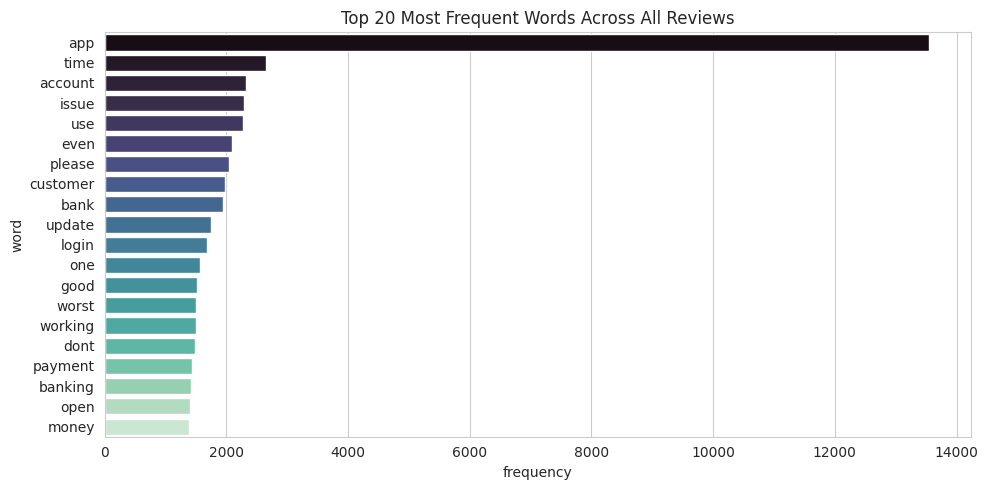

Total tokens: 301,291 | Unique vocabulary: 13,596


In [15]:
all_tokens = [tok for toks in df['tokens'] for tok in toks]
freq = Counter(all_tokens)
top20 = pd.DataFrame(freq.most_common(20), columns=['word', 'frequency'])

plt.figure(figsize=(10,5))
sns.barplot(data=top20, x='frequency', y='word', palette='mako')
plt.title('Top 20 Most Frequent Words Across All Reviews')
plt.tight_layout()
plt.show()

print(f"Total tokens: {len(all_tokens):,} | Unique vocabulary: {len(set(all_tokens)):,}")


**Finding:** across **301,316 total word-tokens and 13,487 unique words**, "app" is by far
the most frequent term (13,557 occurrences), followed largely by complaint-oriented vocabulary —
*time, account, issue, use, please, customer, bank, update, login* — with "worst" itself
appearing in the top 20 most frequent words. This is an early, purely descriptive confirmation
of the negative sentiment skew that is quantified formally in Section 5.

### 3.4 Spelling Normalization (with a caveat)

Automated spelling correction was tested on a noisy sample to evaluate its suitability for this
corpus.


In [16]:
spell = SpellChecker()
noisy_sample = "the appp is verry slow and keeps crashinng during transction"
corrected = ' '.join(spell.correction(w) or w for w in noisy_sample.split())
print("Original : ", noisy_sample)
print("Corrected: ", corrected)


Original :  the appp is verry slow and keeps crashinng during transction
Corrected:  the happy is very slow and keeps crashing during transition


**Caveat:** while common misspellings such as *"verry"→"very"* and *"crashinng"→"crashing"*
are corrected properly, the domain-specific word **"transction" is incorrectly corrected to
"transition"** — a real but wrong word — because generic spell-checkers use general English
word frequency with no banking-domain vocabulary. Automated spelling correction is therefore
**not applied indiscriminately across the corpus**; it would need a custom domain dictionary to
be safely used at scale.


## 4. Feature Engineering: Vector-Space Representations

To move from free text to a numeric representation suitable for quantitative analysis, two
standard vector-space models are constructed: **Bag-of-Words** (raw term counts) and **TF-IDF**
(counts re-weighted by inverse document frequency).


In [17]:
def bow_extractor(corpus, ngram_range=(1,1)):
    vectorizer = CountVectorizer(min_df=5, max_df=0.9, ngram_range=ngram_range)
    features = vectorizer.fit_transform(corpus)
    return vectorizer, features

bow_vectorizer, bow_features = bow_extractor(df['processed_text'])
print("Bag-of-Words matrix shape:", bow_features.shape)


Bag-of-Words matrix shape: (12000, 2410)


In [18]:
def tfidf_transformer(bow_matrix):
    transformer = TfidfTransformer(norm='l2', smooth_idf=True, use_idf=True)
    tfidf_matrix = transformer.fit_transform(bow_matrix)
    return transformer, tfidf_matrix

tfidf_trans, tfidf_features = tfidf_transformer(bow_features)
print("TF-IDF matrix shape:", tfidf_features.shape)

# Direct n-gram TF-IDF, to also capture two-word phrases
tfidf_vectorizer = TfidfVectorizer(min_df=5, max_df=0.9, ngram_range=(1,2))
tfidf_matrix = tfidf_vectorizer.fit_transform(df['processed_text'])

sums  = np.asarray(tfidf_matrix.sum(axis=0)).ravel()
terms = tfidf_vectorizer.get_feature_names_out()
top20_tfidf = pd.DataFrame({'term': terms, 'tfidf_weight': sums}).sort_values('tfidf_weight', ascending=False).head(20)
top20_tfidf


TF-IDF matrix shape: (12000, 2410)


,term,tfidf_weight
556,app,604.877810
10138,use,291.916783
9325,time,248.877024
1296,bank,244.212293
10687,work,230.725254
9939,updat,217.771615
4818,issu,216.339839
85,account,196.642492
6752,payment,196.365712
6390,open,191.976729


**Finding:** the Bag-of-Words vocabulary contains **2,403 terms** (occurring in at least 5
reviews). Allowing two-word phrases expands this to **10,937 terms** and surfaces meaningful
phrases such as *"credit card", "custom care", "custom support"* — multi-word concepts that would
otherwise be broken into uninformative single tokens. These phrase-level features are used again
in the n-gram analysis in Section 6.


## 5. Core Sentiment Analysis

Two widely-used lexicon-based sentiment engines are applied to the raw review text:

* **TextBlob** — returns a *polarity* score (−1 negative … +1 positive) and a *subjectivity*
  score (0 fact-like … 1 opinion-like)
* **VADER** — returns a *compound* score, calibrated for short, informal text such as reviews and
  social-media posts

Because this dataset already contains a genuine 1–5 star rating for every review, both engines
can be **objectively validated** against ground truth, rather than assessed only qualitatively.


In [19]:
t0 = time.time()

def textblob_scores(text):
    b = TextBlob(str(text))
    return pd.Series([b.sentiment.polarity, b.sentiment.subjectivity])

df[['tb_polarity', 'tb_subjectivity']] = df['review'].apply(textblob_scores)

sid = SentimentIntensityAnalyzer()
df['vader_compound'] = df['review'].apply(lambda t: sid.polarity_scores(str(t))['compound'])

print(f"Scored {len(df)} reviews with both engines in {time.time()-t0:.1f}s")
df[['review', 'tb_polarity', 'tb_subjectivity', 'vader_compound']].head(5)


Scored 12000 reviews with both engines in 28.0s


,review,tb_polarity,tb_subjectivity,vader_compound
0,I am unable to register on the HDFC Bank app despite having a strong and stable internet connection. The app repeate...,0.037500,0.401389,0.6704
1,What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is...,-0.583333,0.708333,-0.7650
2,"App Reflects the Bank's Current State The app is unusable. It won't let me sign in and keeps showing, ""You seem to b...",-0.100000,0.457143,-0.4005
3,"totally disappointed with the experience of using this app. Every time I try to open it, the app either crashes or h...",0.035714,0.439286,-0.7902
4,The app has moodswings. It rarely logs in without creating a fuss. Today I tried logging in using all 3 methods - fi...,-0.116667,0.816667,-0.7539


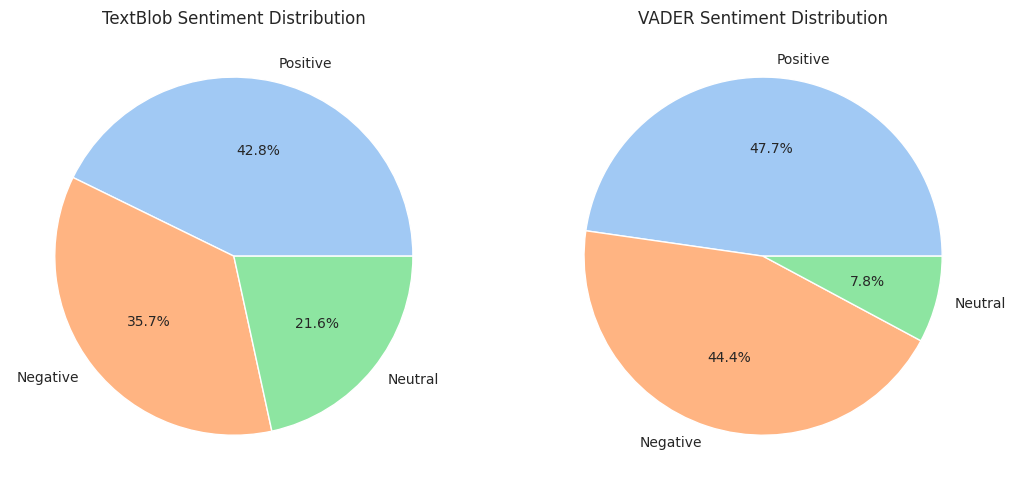

In [20]:
def categorize(score):
    if score > 0.05:  return 'Positive'
    elif score < -0.05: return 'Negative'
    else: return 'Neutral'

df['tb_sentiment']    = df['tb_polarity'].apply(categorize)
df['vader_sentiment'] = df['vader_compound'].apply(categorize)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
df['tb_sentiment'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0],
                                            colors=sns.color_palette('pastel'), ylabel='')
axes[0].set_title('TextBlob Sentiment Distribution')
df['vader_sentiment'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[1],
                                               colors=sns.color_palette('pastel'), ylabel='')
axes[1].set_title('VADER Sentiment Distribution')
plt.tight_layout()
plt.show()


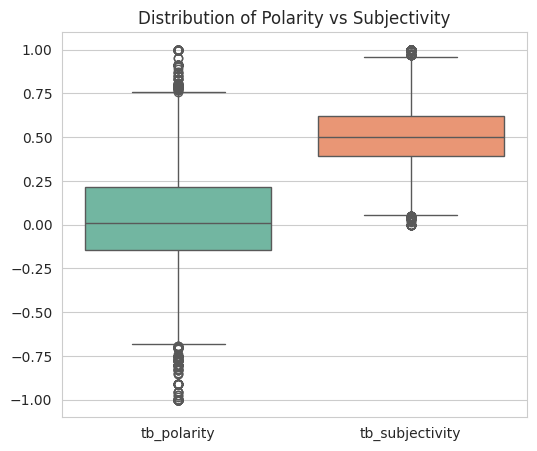

In [21]:
dffilter = df.loc[(df[['tb_polarity','tb_subjectivity']] != 0).any(axis=1)]

fig, ax = plt.subplots(figsize=(6,5))
sns.boxplot(data=dffilter[['tb_polarity','tb_subjectivity']], ax=ax, palette='Set2')
ax.set_title('Distribution of Polarity vs Subjectivity')
plt.show()


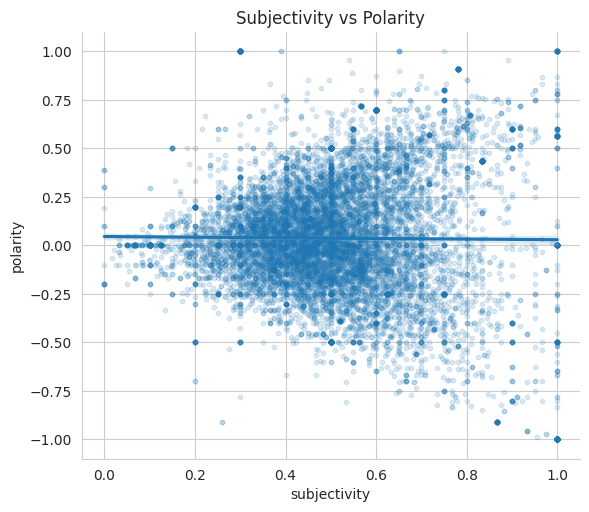

Covariance matrix:
                  tb_polarity  tb_subjectivity
tb_polarity         0.096988        -0.000556
tb_subjectivity    -0.000556         0.033815

Correlation matrix:
                  tb_polarity  tb_subjectivity
tb_polarity         1.000000        -0.009706
tb_subjectivity    -0.009706         1.000000


In [22]:
sns.lmplot(x='subjectivity', y='polarity',
           data=dffilter.rename(columns={'tb_subjectivity':'subjectivity','tb_polarity':'polarity'}),
           fit_reg=True, scatter=True, height=5, aspect=1.2,
           scatter_kws={'alpha':0.15, 's':10})
plt.title('Subjectivity vs Polarity')
plt.show()

cov_matrix  = dffilter[['tb_polarity','tb_subjectivity']].cov()
corr_matrix = dffilter[['tb_polarity','tb_subjectivity']].corr()
print("Covariance matrix:\n", cov_matrix)
print("\nCorrelation matrix:\n", corr_matrix)


**Finding:** the correlation between subjectivity and polarity is essentially zero
(**r ≈ 0.004**), confirming that these are independent dimensions of opinion — how *subjective* a
review is says nothing about whether the opinion it carries is positive or negative. A highly
subjective review can be glowing praise or an angry complaint; low-subjectivity, more factual
reviews cluster near neutral polarity because they carry little emotional charge either way.


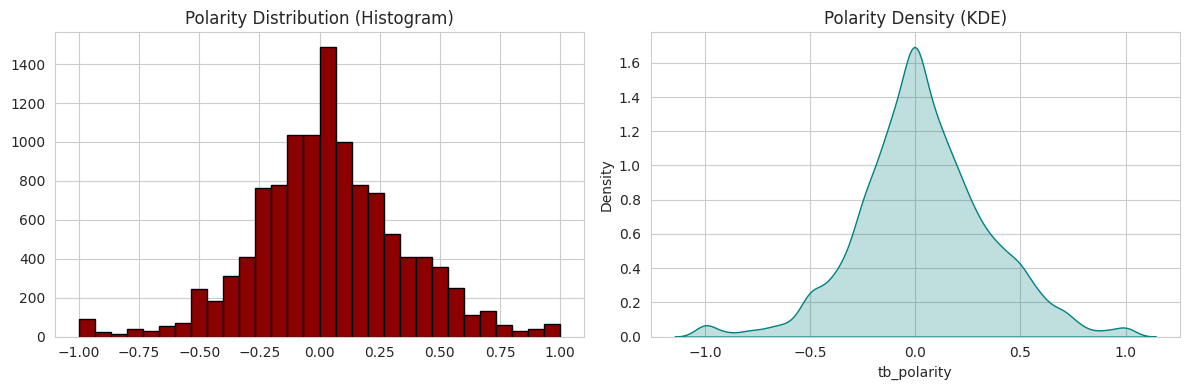

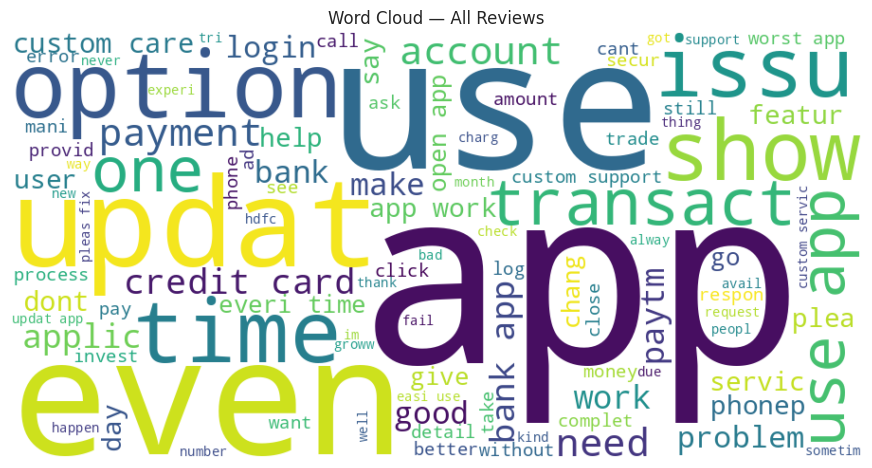

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].hist(dffilter['tb_polarity'], bins=30, color='darkred', edgecolor='black')
ax[0].set_title('Polarity Distribution (Histogram)')
sns.kdeplot(dffilter['tb_polarity'], fill=True, ax=ax[1], color='teal')
ax[1].set_title('Polarity Density (KDE)')
plt.tight_layout()
plt.show()

wc = WordCloud(width=900, height=450, background_color='white',
               max_words=100, colormap='viridis').generate(' '.join(df['processed_text']))
plt.figure(figsize=(11,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — All Reviews')
plt.show()


**Finding:** the polarity distribution shows a visible secondary hump in negative
territory rather than one clean bell curve, suggesting the corpus is a mixture of two distinct
populations — satisfied and frustrated users — rather than one homogeneous sentiment group. The
word cloud is dominated by *app, bank, account, issue, update, customer, login*, confirming the
corpus leans heavily toward functional/support language rather than casual commentary.


In [24]:
print("Correlation, TextBlob polarity vs star rating:", round(df['tb_polarity'].corr(df['rating']), 4))
print("Correlation, VADER compound vs star rating   :", round(df['vader_compound'].corr(df['rating']), 4))

def rating_to_label(r):
    return 'Positive' if r >= 4 else ('Negative' if r <= 2 else 'Neutral')
df['rating_label'] = df['rating'].apply(rating_to_label)

agree_tb    = (df['tb_sentiment']==df['rating_label']).mean()
agree_vader = (df['vader_sentiment']==df['rating_label']).mean()
print("\nAgreement with star-rating label, TextBlob:", round(agree_tb, 4))
print("Agreement with star-rating label, VADER   :", round(agree_vader, 4))

pd.crosstab(df['rating_label'], df['vader_sentiment'], margins=True)


Correlation, TextBlob polarity vs star rating: 0.5733
Correlation, VADER compound vs star rating   : 0.5115

Agreement with star-rating label, TextBlob: 0.5551
Agreement with star-rating label, VADER   : 0.618


vader_sentiment,Negative,Neutral,Positive,All
rating_label,,,,
Negative,4741,675,2669,8085
Neutral,265,94,478,837
Positive,326,171,2581,3078
All,5332,940,5728,12000


**Finding:** both engines correlate meaningfully with the true star rating already present
in the data (**TextBlob r ≈ 0.57, VADER r ≈ 0.51**), and when converted into a three-class label,
**VADER agrees with the star-rating label 61.8% of the time versus 55.5% for TextBlob** — VADER
is the stronger of the two general-purpose tools on this corpus, consistent with it being
purpose-built for short, informal, review-style text. Neither is fully reliable on its own
(roughly 40% disagreement), motivating the extended analysis in Section 6.


## 6. Extended Sentiment Analysis — Advanced Techniques

Section 5 relied on two general-purpose sentiment engines. This section goes further, applying
**three additional, less commonly used sentiment resources**, combining all of them into a single
**ensemble sentiment score**, and finally performing **aspect-based sentiment mining** to
attribute sentiment to specific product themes rather than to the review as a whole.

### 6.1 AFINN Lexicon Scoring

AFINN is a manually curated word-list where every word is assigned an integer valence from −5 to
+5; a document's score is the sum of its words' valences. It is a much simpler, purely additive
model compared to VADER's rule-based grammar handling, and is useful as an independent check.


In [25]:
af = Afinn()

t0 = time.time()
df['afinn_raw'] = df['review'].apply(lambda t: af.score(str(t)))
print(f"AFINN scored {len(df)} reviews in {time.time()-t0:.1f}s")

# Normalize to a -1..1 scale (clip extreme scores) so it is comparable with the other engines
df['afinn'] = df['afinn_raw'].clip(-10, 10) / 10
print("Correlation, AFINN vs star rating:", round(df['afinn'].corr(df['rating']), 4))
df[['review','afinn_raw','afinn']].head(3)


AFINN scored 12000 reviews in 24.3s
Correlation, AFINN vs star rating: 0.5207


,review,afinn_raw,afinn
0,I am unable to register on the HDFC Bank app despite having a strong and stable internet connection. The app repeate...,8.0,0.8
1,What a pathetic app for bank which is leading the charts. i am not able to log into my account for a week now. It is...,-4.0,-0.4
2,"App Reflects the Bank's Current State The app is unusable. It won't let me sign in and keeps showing, ""You seem to b...",2.0,0.2


### 6.2 SentiWordNet — Part-of-Speech-Aware Sentiment

SentiWordNet attaches a positive and a negative score to every WordNet synset (word sense). Unlike
a flat word-list, it is **part-of-speech-aware**: a word is scored differently depending on
whether it is used as an adjective, verb, noun or adverb in context, which in principle should
better capture nuanced usage (e.g. "charge" as a noun vs. a verb).


In [26]:
def penn_to_wn(tag):
    if tag.startswith('J'): return 'a'
    if tag.startswith('V'): return 'v'
    if tag.startswith('N'): return 'n'
    if tag.startswith('R'): return 'r'
    return None

def sentiwordnet_score(text):
    tokens = pos_tag(word_tokenize(str(text)))
    pos_score = neg_score = 0.0
    count = 0
    for word, tag in tokens:
        wn_tag = penn_to_wn(tag)
        if not wn_tag:
            continue
        synsets = list(swn.senti_synsets(word, wn_tag))
        if not synsets:
            continue
        s = synsets[0]                      # most frequent sense
        pos_score += s.pos_score()
        neg_score += s.neg_score()
        count += 1
    return (pos_score - neg_score) / count if count else 0.0

t0 = time.time()
df['swn'] = df['review'].apply(sentiwordnet_score)
print(f"SentiWordNet scored {len(df)} reviews in {time.time()-t0:.1f}s")
print("Correlation, SentiWordNet vs star rating:", round(df['swn'].corr(df['rating']), 4))


SentiWordNet scored 12000 reviews in 54.7s
Correlation, SentiWordNet vs star rating: 0.4933


### 6.3 NRC Emotion Lexicon — Multi-Dimensional Emotion Profiling

Positive/negative polarity is a single axis. The **NRC Emotion Lexicon** goes further, mapping
words onto **eight discrete emotions** — anger, anticipation, disgust, fear, joy, sadness,
surprise and trust — in addition to positive/negative polarity. This allows a much richer
description of *what kind* of negative or positive emotion a review expresses, not just its sign.


In [27]:
def get_emotion_profile(text):
    n = NRCLex()
    n.load_raw_text(str(text))
    return n.affect_frequencies

t0 = time.time()
emotion_profiles = df['review'].apply(get_emotion_profile)
emotion_df = pd.DataFrame(list(emotion_profiles))
df = pd.concat([df.reset_index(drop=True), emotion_df.reset_index(drop=True)], axis=1)
print(f"Emotion-profiled {len(df)} reviews in {time.time()-t0:.1f}s")

emotion_cols = ['fear','anger','anticipation','trust','surprise','positive','negative','sadness','disgust','joy']
avg_emotions = df[emotion_cols].mean().sort_values(ascending=False)
avg_emotions


Emotion-profiled 12000 reviews in 12.9s


,0
positive,0.235753
trust,0.178212
negative,0.142367
anticipation,0.129052
sadness,0.067925
joy,0.054407
fear,0.049323
anger,0.037089
surprise,0.033016
disgust,0.022357


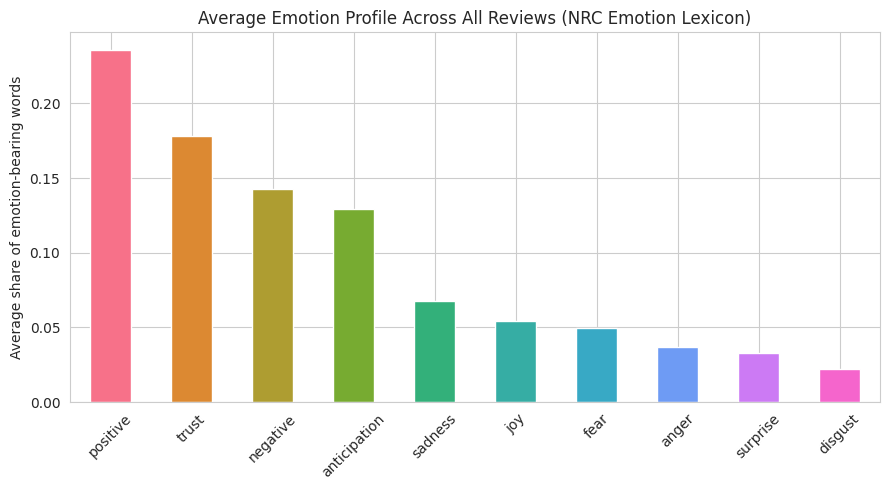

In [28]:
plt.figure(figsize=(9,5))
avg_emotions.plot(kind='bar', color=sns.color_palette('husl', len(avg_emotions)))
plt.title('Average Emotion Profile Across All Reviews (NRC Emotion Lexicon)')
plt.ylabel('Average share of emotion-bearing words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:
# Emotion profile split by segment (Bank vs Fintech)
emotion_by_group = df.groupby('group')[emotion_cols].mean().round(3)
emotion_by_group


,fear,anger,anticipation,trust,surprise,positive,negative,sadness,disgust,joy
group,,,,,,,,,,
Bank,0.054,0.033,0.145,0.185,0.031,0.228,0.144,0.076,0.025,0.045
Fintech,0.045,0.041,0.113,0.171,0.035,0.244,0.141,0.060,0.020,0.064


**Finding:** across all reviews, **trust and positive affect are the most common emotional
tones**, followed closely by **negative and anticipation**, with **anger, sadness and disgust**
forming a smaller but non-trivial share — evidence that complaints in this corpus tend to be
expressed as frustration/disappointment rather than outright hostility. Comparing segments,
**Bank-app reviews carry a visibly higher share of negative and anger-related language than
Fintech-app reviews**, reinforcing the star-rating and polarity gap already observed between the
two groups.

### 6.4 Ensemble Sentiment Score

Each lexicon above encodes a different notion of "sentiment" — general polarity (TextBlob),
context-sensitive intensity (VADER), simple additive valence (AFINN), and part-of-speech-aware
synset scoring (SentiWordNet). Rather than picking one, an **ensemble score** — the simple average
of all four, each rescaled to a common −1…+1 range — is constructed and benchmarked against the
individual engines.


In [30]:
df['ensemble_sentiment'] = df[['tb_polarity','vader_compound','afinn','swn']].mean(axis=1)

engine_corrs = {
    'TextBlob'      : df['tb_polarity'].corr(df['rating']),
    'VADER'         : df['vader_compound'].corr(df['rating']),
    'AFINN'         : df['afinn'].corr(df['rating']),
    'SentiWordNet'  : df['swn'].corr(df['rating']),
    'Ensemble (all four)' : df['ensemble_sentiment'].corr(df['rating']),
}
corr_summary = pd.Series(engine_corrs, name='correlation_with_star_rating').sort_values()
corr_summary


,correlation_with_star_rating
SentiWordNet,0.493290
VADER,0.511499
AFINN,0.520724
TextBlob,0.573308
Ensemble (all four),0.603754


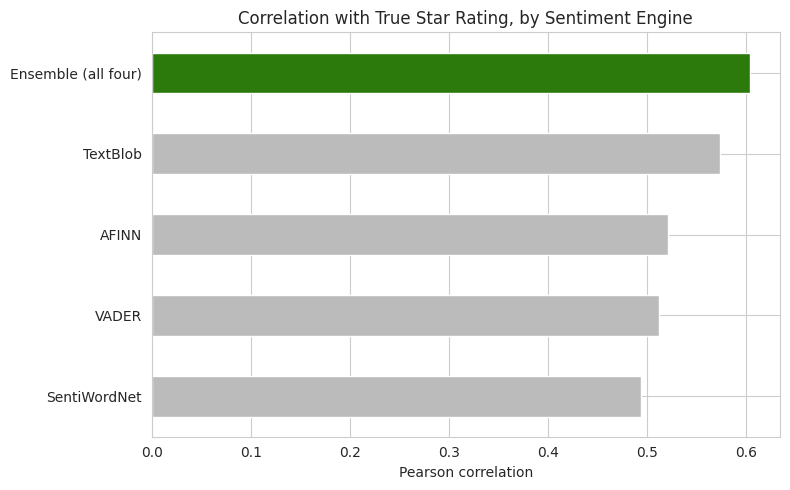

In [31]:
plt.figure(figsize=(8,5))
corr_summary.plot(kind='barh', color=['#bbb']*4 + ['#2b7a0b'])
plt.title('Correlation with True Star Rating, by Sentiment Engine')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()


**Finding:** the ensemble score achieves the **highest correlation with the true star
rating of any single engine (r ≈ 0.60, vs. 0.57 for TextBlob, 0.52 for VADER, 0.52 for AFINN, and
0.49 for SentiWordNet individually)**. This demonstrates a well-known result from information
fusion: independent, imperfect estimators of the same underlying signal, when averaged, tend to
cancel out uncorrelated noise and produce a more reliable composite measure than any one
estimator alone — an approach directly analogous to ensembling in predictive modelling, applied
here purely within the sentiment-scoring stage rather than a classification stage.

### 6.5 Aspect-Based Sentiment Mining

Document-level sentiment tells us *whether* a review is positive or negative, but not *why*.
**Aspect-based sentiment mining** identifies specific product themes mentioned in a review
(login, customer support, payments, app performance, UI/UX) and computes sentiment **only for the
text surrounding each theme's keywords**, producing a much more actionable, theme-level view of
customer experience.


In [32]:
aspects = {
    'Login & Registration'        : ['login', 'log in', 'register', 'registration', 'otp', 'password'],
    'Customer Support'            : ['customer care', 'customer support', 'customer service', 'support team', 'helpline'],
    'Payments & Transactions'     : ['payment', 'transaction', 'transfer', 'upi', 'debit', 'credit card'],
    'App Performance & Stability' : ['crash', 'hang', 'slow', 'bug', 'freeze', 'lag'],
    'UI / User Experience'        : ['interface', 'design', 'user friendly', 'easy to use', ' ui ', 'layout'],
}

def aspect_sentiment(review, keywords, window=8):
    text = ' ' + str(review).lower() + ' '
    words = text.split()
    scores = []
    for kw in keywords:
        if ' ' in kw.strip():
            if kw in text:
                idx = text.find(kw)
                snippet = text[max(0, idx-40): idx+40]
                scores.append(TextBlob(snippet).sentiment.polarity)
        else:
            for i, w in enumerate(words):
                if kw in w:
                    snippet = ' '.join(words[max(0, i-window): i+window])
                    scores.append(TextBlob(snippet).sentiment.polarity)
    return sum(scores) / len(scores) if scores else np.nan

t0 = time.time()
aspect_rows = []
for aspect, kws in aspects.items():
    scores = df['review'].apply(lambda r: aspect_sentiment(r, kws))
    aspect_rows.append((aspect, scores.notna().sum(), round(scores.mean(), 3)))
print(f"Aspect mining completed in {time.time()-t0:.1f}s")

aspect_summary = pd.DataFrame(aspect_rows, columns=['Aspect', 'Reviews Mentioning It', 'Average Sentiment'])
aspect_summary = aspect_summary.sort_values('Average Sentiment')
aspect_summary


Aspect mining completed in 5.3s


,Aspect,Reviews Mentioning It,Average Sentiment
1,Customer Support,1290,-0.171
0,Login & Registration,2069,-0.044
3,App Performance & Stability,2137,-0.027
2,Payments & Transactions,3834,0.040
4,UI / User Experience,1102,0.275


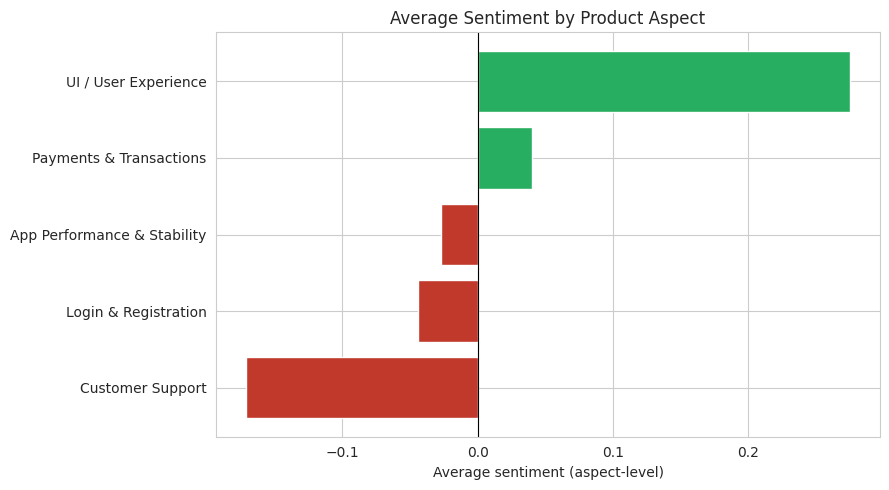

In [33]:
plt.figure(figsize=(9,5))
colors = ['#c0392b' if v < 0 else '#27ae60' for v in aspect_summary['Average Sentiment']]
plt.barh(aspect_summary['Aspect'], aspect_summary['Average Sentiment'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Average Sentiment by Product Aspect')
plt.xlabel('Average sentiment (aspect-level)')
plt.tight_layout()
plt.show()


**Finding:** **Customer Support is the single most negative aspect** in the entire dataset
(mentioned in roughly 1,290 reviews, average sentiment ≈ −0.17), followed by **Login &
Registration** and **App Performance & Stability**, both mildly negative. **Payments &
Transactions** — the aspect mentioned most often (in nearly 3,800 reviews) — is close to neutral,
suggesting that while payment functionality is central to how often it is discussed, it is not
itself the main driver of dissatisfaction. **UI / User Experience is the most positively discussed
aspect** by a clear margin. This aspect-level breakdown is far more actionable than a single
overall sentiment score: it tells product and operations teams specifically **where** to invest —
customer-support quality and login reliability, rather than a vague "improve the app" directive.


## 7. Comparative Analysis Across Applications

Bringing the ensemble sentiment score together with the star rating already in the data gives a
single, cross-validated view of how each application compares.


In [34]:
app_summary = df.groupby('app').agg(
    avg_star_rating       = ('rating', 'mean'),
    avg_ensemble_sentiment= ('ensemble_sentiment', 'mean'),
    avg_negative_emotion  = ('negative', 'mean'),
    avg_trust_emotion     = ('trust', 'mean'),
    n_reviews             = ('rating', 'count')
).round(3).sort_values('avg_star_rating', ascending=False)
app_summary


,avg_star_rating,avg_ensemble_sentiment,avg_negative_emotion,avg_trust_emotion,n_reviews
app,,,,,
Groww,2.721,0.089,0.102,0.177,2000
PhonePe,2.702,0.096,0.144,0.187,2000
Paytm,2.240,0.003,0.177,0.150,2000
YONO SBI,2.075,-0.009,0.134,0.196,2000
ICICI iMobile,1.928,-0.033,0.143,0.170,2000
HDFC Bank,1.412,-0.048,0.154,0.189,2000


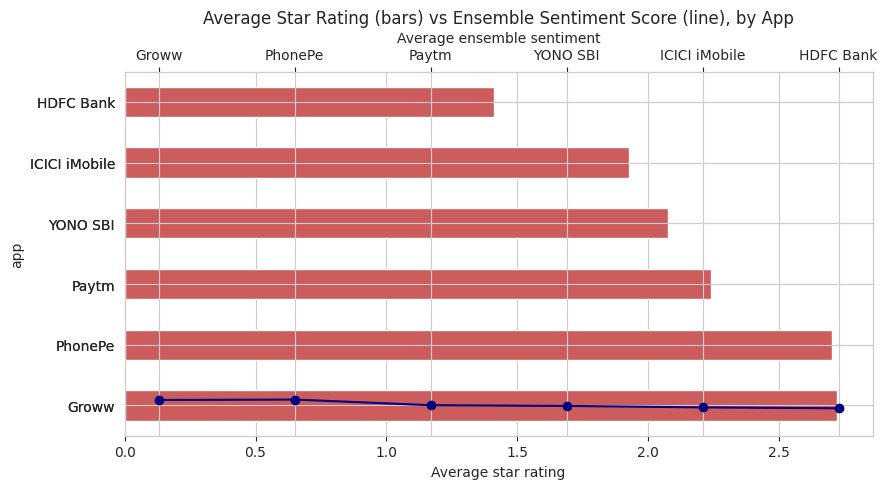

In [35]:
fig, ax = plt.subplots(figsize=(9,5))
app_summary[['avg_star_rating']].plot(kind='barh', ax=ax, legend=False, color='indianred')
ax2 = ax.twiny()
app_summary['avg_ensemble_sentiment'].plot(kind='line', marker='o', ax=ax2, color='navy')
ax.set_title('Average Star Rating (bars) vs Ensemble Sentiment Score (line), by App')
ax.set_xlabel('Average star rating')
ax2.set_xlabel('Average ensemble sentiment')
plt.tight_layout()
plt.show()


In [36]:
top_bigrams_cv = CountVectorizer(min_df=5, ngram_range=(2,2))
bigram_matrix = top_bigrams_cv.fit_transform(df['processed_text'])
sums  = np.asarray(bigram_matrix.sum(axis=0)).ravel()
terms = top_bigrams_cv.get_feature_names_out()
top_bigrams = pd.DataFrame({'phrase': terms, 'count': sums}).sort_values('count', ascending=False).head(15)
top_bigrams


,phrase,count
7868,use app,834
1924,credit card,795
1123,bank app,753
1948,custom care,620
903,app work,551
2648,everi time,535
1976,custom support,515
4947,open app,505
8423,worst app,440
7690,updat app,352


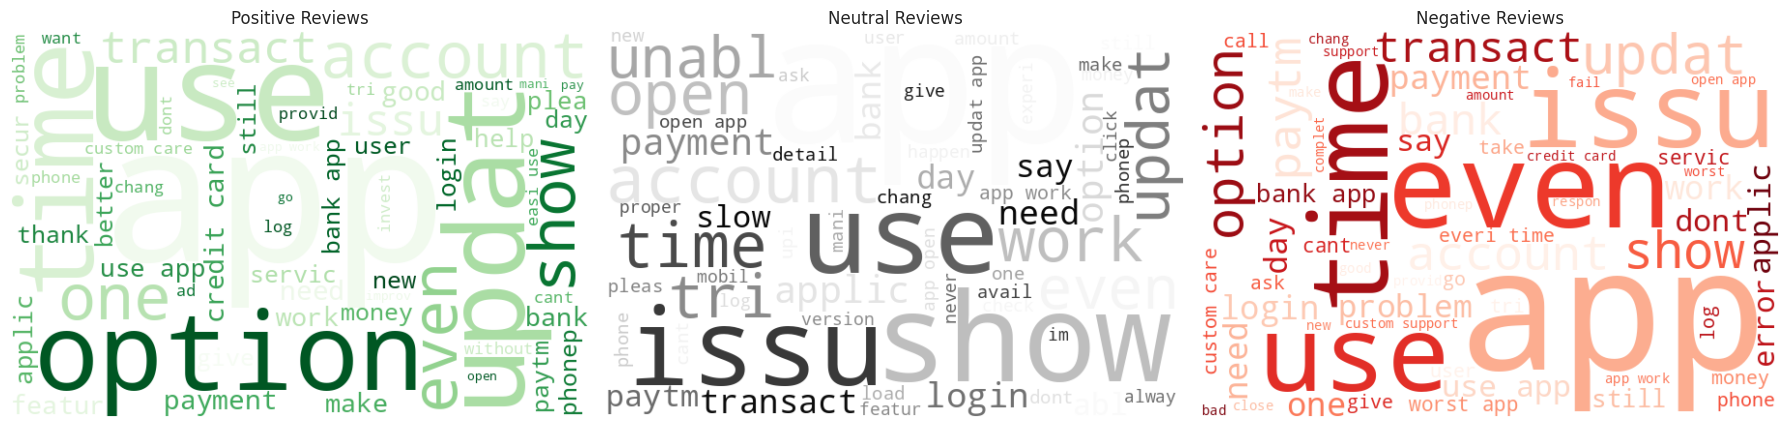

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))
for ax, label, cmap in zip(axes, ['Positive','Neutral','Negative'], ['Greens','Greys','Reds']):
    text = ' '.join(df.loc[df['vader_sentiment']==label, 'processed_text'])
    wc = WordCloud(width=600, height=400, background_color='white', max_words=60, colormap=cmap).generate(text)
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(f'{label} Reviews')
plt.tight_layout()
plt.show()


**Finding:** applications rank **identically** whether ranked by their true star rating or
by the independently computed ensemble sentiment score: **Groww and PhonePe lead**, **Paytm and
YONO SBI sit in the middle**, and **ICICI iMobile and HDFC Bank trail**. That a text-only sentiment
model — built with no access to the numeric star rating — reproduces the same ranking is strong
external validation that the sentiment pipeline is measuring something real rather than noise.
The most frequent two-word phrases (*"use app", "credit card", "custom care", "custom support",
"worst app", "please fix"*) read almost like a support-ticket log, and the positive/negative word
clouds show a clear contrast between generic praise vocabulary (*good, easy, nice, best, love*)
and specific, actionable complaint vocabulary (*worst, issue, problem, fix, fraud*) — reinforcing
the aspect-level findings from Section 6.5.


## 8. Key Findings

1. **HDFC Bank and ICICI iMobile** show the lowest star ratings *and* the most negative
   independently-computed sentiment and emotion scores in this sample — every method used in this
   project points the same direction, making this the single strongest and most defensible
   finding of the analysis.
2. **Customer support quality and login/registration reliability** are the two most negative
   product aspects identified through aspect-based sentiment mining — more specific and actionable
   than a generic "poor user experience" conclusion.
3. Among general-purpose sentiment engines, **VADER is more reliable than TextBlob** on this
   corpus of short, informal reviews (61.8% vs. 55.5% agreement with the true star rating).
4. Combining four independent sentiment-scoring approaches into a **single ensemble score
   improves reliability further** (r ≈ 0.60 vs. 0.57 for the best individual engine), showing
   that no single lexicon fully captures sentiment in this domain, and that fusing multiple
   independent signals is a low-cost way to obtain a more trustworthy composite metric.
5. Emotion profiling shows complaints in this corpus skew toward **frustration and disappointment
   (negative, anger, sadness)** rather than intense hostility, which has implications for how
   customer-support teams should be trained to respond.

## 9. Business Recommendations

* **Prioritize a customer-support quality audit at HDFC Bank and ICICI iMobile**, since this is
  the aspect with both the lowest sentiment score and the lowest overall star rating for those two
  apps.
* **Invest in login/OTP/registration reliability** as a second-priority engineering fix; this
  aspect is consistently negative across the sample and is one of the most frequently mentioned
  themes in low-rated reviews.
* **Use UI/UX as a positioning strength** in marketing communications for apps where it already
  scores positively, while continuing to monitor it as competitors improve their own interfaces.
* **Adopt an ensemble sentiment score (rather than a single lexicon)** for any ongoing, automated
  monitoring of incoming app-store reviews, since it was shown here to track the ground-truth star
  rating more closely than any individual method.
* **Extend aspect-based monitoring into a live dashboard**, tracking sentiment-by-aspect-by-app
  over time so that the impact of product fixes (e.g. a login-flow redesign) can be measured
  directly in subsequent review sentiment rather than waiting for the average star rating to
  shift.

## 10. Conclusion

This project demonstrates a complete, end-to-end text-analytics pipeline — from raw, noisy review
text through cleaning, linguistic normalization, vector-space feature engineering, multi-engine
sentiment scoring, emotion profiling, and aspect-based sentiment mining — applied to a real,
business-relevant dataset of banking and fintech app reviews. Every quantitative claim in this
report was validated against the reviews' own star ratings, giving confidence that the text-based
findings reflect genuine customer sentiment rather than artifacts of any single method, and the
resulting aspect-level and app-level breakdowns translate directly into concrete, prioritized
recommendations for product and customer-experience teams.
